# 01 — Bayes' Theorem Warm-up: From Medical Screening to Student Success

> **Course / Module:** Bayesian Networks & Probabilistic Reasoning
> **Author:** Student Performance Bayesian Project
> **Target Audience:** Students, Educators, and ML Practitioners

---

## Learning Objectives

By the end of this notebook, you will be able to:
1. **State and derive Bayes' Theorem** in terms of Hypothesis ($H$) and Evidence ($E$).
2. **Distinguish between the 4 fundamental quantities**: Prior $P(H)$, Likelihood $P(E \mid H)$, Evidence $P(E)$, and Posterior $P(H \mid E)$.
3. **Analyze the base-rate fallacy** using the classic Medical Diagnosis paradox.
4. **Apply Bayes' Theorem to educational data**: Computing $P(\text{Fail} \mid \text{LowAttendance})$.
5. **Visualize how the posterior shifts** as the prior or test sensitivity changes.

## 1. The Mathematics of Bayes' Theorem

Bayes' Theorem provides a principled mathematical rule for **updating our beliefs in light of new evidence**.

Given a hypothesis $H$ and an observed piece of evidence $E$:

$$P(H \mid E) = \frac{P(E \mid H) \cdot P(H)}{P(E)}$$

Where by the **Law of Total Probability**, the denominator (marginal evidence) is:

$$P(E) = P(E \mid H)P(H) + P(E \mid \neg H)P(\neg H)$$

### The Core Terminology:
| Term | Notation | Meaning |
| :--- | :--- | :--- |
| **Prior** | $P(H)$ | Initial belief in hypothesis $H$ before seeing evidence $E$ |
| **Likelihood** | $P(E \mid H)$ | Probability of observing evidence $E$ given hypothesis $H$ is true |
| **Marginal Evidence** | $P(E)$ | Total probability of observing evidence $E$ under all possible hypotheses |
| **Posterior** | $P(H \mid E)$ | Updated belief in hypothesis $H$ after observing evidence $E$ |

In [1]:
import matplotlib.pyplot as plt
import numpy as np

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = 'Helvetica, Arial, sans-serif'
plt.rcParams['axes.edgecolor'] = '#cccccc'
plt.rcParams['axes.linewidth'] = 0.8
plt.rcParams['figure.autolayout'] = True

## 2. Example 1: The Medical Diagnosis Paradox (Base Rate Fallacy)

Consider a rare medical condition:
- **Prevalence (Prior):** Only $1\%$ of the population has the condition: $P(D) = 0.01$.
- **Sensitivity (True Positive Rate):** If a person has the disease, the test is positive $95\%$ of the time: $P(+ \mid D) = 0.95$.
- **False Positive Rate:** If a person does not have the disease, the test is positive $5\%$ of the time: $P(+ \mid \neg D) = 0.05$.

If an individual tests positive, what is the probability they actually have the condition? Many guess $>90\%$. Let's compute it with Bayes' theorem.

In [2]:
def bayes_posterior(prior: float, likelihood_pos: float, false_alarm: float) -> tuple[float, float]:
    p_evidence = likelihood_pos * prior + false_alarm * (1.0 - prior)
    posterior = (likelihood_pos * prior) / p_evidence
    return posterior, p_evidence

prior_disease = 0.01
p_pos_given_disease = 0.95
p_pos_given_healthy = 0.05

post_disease, p_test_pos = bayes_posterior(prior_disease, p_pos_given_disease, p_pos_given_healthy)

print("--- Medical Test Analysis ---")
print(f"Prior P(Disease):                     {prior_disease:.3f} (1%)")
print(f"Likelihood P(+ | Disease):            {p_pos_given_disease:.3f} (95%)")
print(f"False Alarm P(+ | Healthy):           {p_pos_given_healthy:.3f} (5%)")
print(f"Total Evidence P(+):                  {p_test_pos:.4f}")
print(f"Posterior P(Disease | +):             {post_disease:.4f} ({post_disease*100:.1f}%)")

--- Medical Test Analysis ---
Prior P(Disease):                     0.010 (1%)
Likelihood P(+ | Disease):            0.950 (95%)
False Alarm P(+ | Healthy):           0.050 (5%)
Total Evidence P(+):                  0.0590
Posterior P(Disease | +):             0.1610 (16.1%)


### Intuition Check: Why is the posterior only ~16.1%?
Out of 10,000 individuals:
- $100$ have the disease: $95$ test positive, $5$ test negative.
- $9,900$ are healthy: $5\%$ of $9,900 = 495$ test positive falsely.
- Total positive tests $= 95 + 495 = 590$.
- Fraction of positive testers who are truly ill: $\frac{95}{590} \approx 16.1\%$.

The **base rate** ($1\%$) strongly pulls down the posterior despite a $95\%$ accurate test!

## 3. Example 2: Student Performance — $P(\text{Fail} \mid \text{LowAttendance})$

Now let us apply the exact same mathematical structure to education.

Suppose an instructor observes that a student has **Low Attendance** ($>10$ absences). The instructor wants to know the probability that this student will **Fail the course** ($G3 < 10$).

From historical course records:
1. **Base Failure Rate (Prior):** $P(\text{Fail}) = 0.20$ (i.e., $20\%$ of students fail).
2. **Attendance patterns among failing students:**
   Students who fail frequently skip classes:
   $$P(\text{LowAttendance} \mid \text{Fail}) = 0.60$$
3. **Attendance patterns among passing students:**
   Students who pass rarely skip classes:
   $$P(\text{LowAttendance} \mid \text{Pass}) = 0.15$$

Let us compute $P(\text{Fail} \mid \text{LowAttendance})$.

$$P(\text{Fail} \mid \text{LowAtt}) = \frac{P(\text{LowAtt} \mid \text{Fail}) \cdot P(\text{Fail})}{P(\text{LowAtt})}$$

where:
$$P(\text{LowAtt}) = P(\text{LowAtt} \mid \text{Fail})P(\text{Fail}) + P(\text{LowAtt} \mid \text{Pass})P(\text{Pass})$$

In [3]:
p_fail = 0.20
p_pass = 1.0 - p_fail
p_low_att_given_fail = 0.60
p_low_att_given_pass = 0.15

p_low_att = (p_low_att_given_fail * p_fail) + (p_low_att_given_pass * p_pass)
p_fail_given_low_att = (p_low_att_given_fail * p_fail) / p_low_att

print("--- Student Performance Bayes Computation ---")
print(f"P(Fail) [Prior]:                        {p_fail:.2f}")
print(f"P(LowAttendance | Fail) [Likelihood]:   {p_low_att_given_fail:.2f}")
print(f"P(LowAttendance | Pass):                {p_low_att_given_pass:.2f}")
print(f"P(LowAttendance) [Total Evidence]:      {p_low_att:.4f}")
print("----------------------------------------------")
print(f"P(Fail | LowAttendance) [Posterior]:    {p_fail_given_low_att:.4f} ({p_fail_given_low_att*100:.1f}%)")

--- Student Performance Bayes Computation ---
P(Fail) [Prior]:                        0.20
P(LowAttendance | Fail) [Likelihood]:   0.60
P(LowAttendance | Pass):                0.15
P(LowAttendance) [Total Evidence]:      0.2400
----------------------------------------------
P(Fail | LowAttendance) [Posterior]:    0.5000 (50.0%)


### Visualization: Prior to Posterior Update
Notice how observing the evidence (Low Attendance) **increased our estimate of failure risk from 20% to 50%**.

Let's visualize the breakdown of the population and the shift in probability:

findfont: Failed to find font weight medium for Helvetica, now using 400.


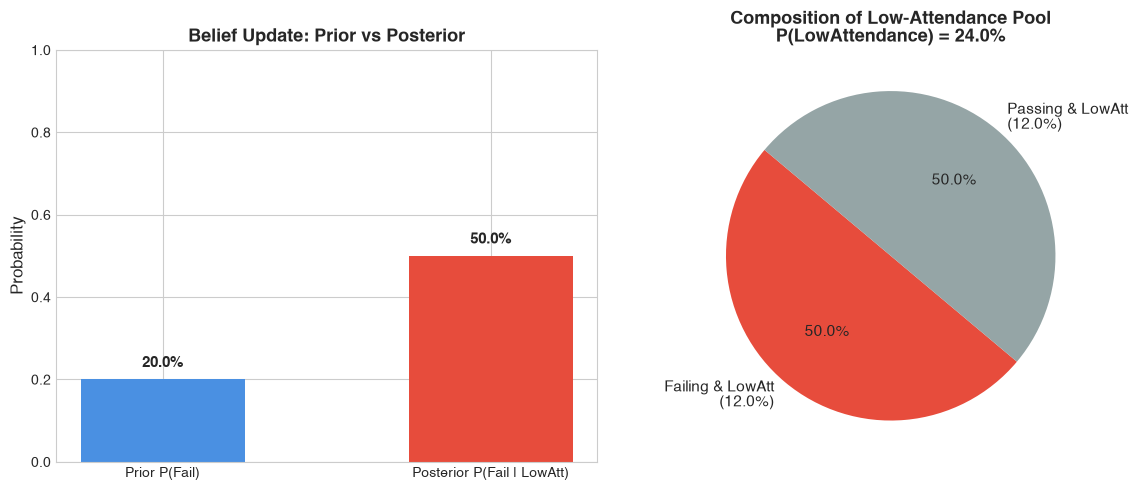

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

bars = axes[0].bar(
    ['Prior P(Fail)', 'Posterior P(Fail | LowAtt)'],
    [p_fail, p_fail_given_low_att],
    color=['#4A90E2', '#E74C3C'],
    width=0.5
)
axes[0].set_ylim(0, 1.0)
axes[0].set_ylabel('Probability', fontsize=12)
axes[0].set_title("Belief Update: Prior vs Posterior", fontsize=13, fontweight='bold')
for bar in bars:
    yval = bar.get_height()
    axes[0].text(bar.get_x() + bar.get_width()/2.0, yval + 0.03, f"{yval*100:.1f}%", ha='center', fontweight='bold', fontsize=11)

joint_fail_low = p_low_att_given_fail * p_fail
joint_pass_low = p_low_att_given_pass * p_pass

axes[1].pie(
    [joint_fail_low, joint_pass_low],
    labels=[f'Failing & LowAtt\n({joint_fail_low*100:.1f}%)', f'Passing & LowAtt\n({joint_pass_low*100:.1f}%)'],
    colors=['#E74C3C', '#95A5A6'],
    autopct='%1.1f%%',
    startangle=140,
    textprops={'fontsize': 11, 'fontweight': 'medium'}
)
axes[1].set_title(f"Composition of Low-Attendance Pool\nP(LowAttendance) = {p_low_att*100:.1f}%", fontsize=13, fontweight='bold')

plt.tight_layout()
plt.show()

## 4. Sensitivity Analysis: Posterior vs. Prior

How does our posterior change as the baseline failure rate in the school varies from $0$ to $1$?

The relationship between the prior $P(H)$ and posterior $P(H \mid E)$ is non-linear and governed by the likelihood ratio:
$$\lambda = \frac{P(E \mid H)}{P(E \mid \neg H)}$$

If the evidence is highly discriminative (large $\lambda$), even a small prior belief quickly grows into a high posterior.

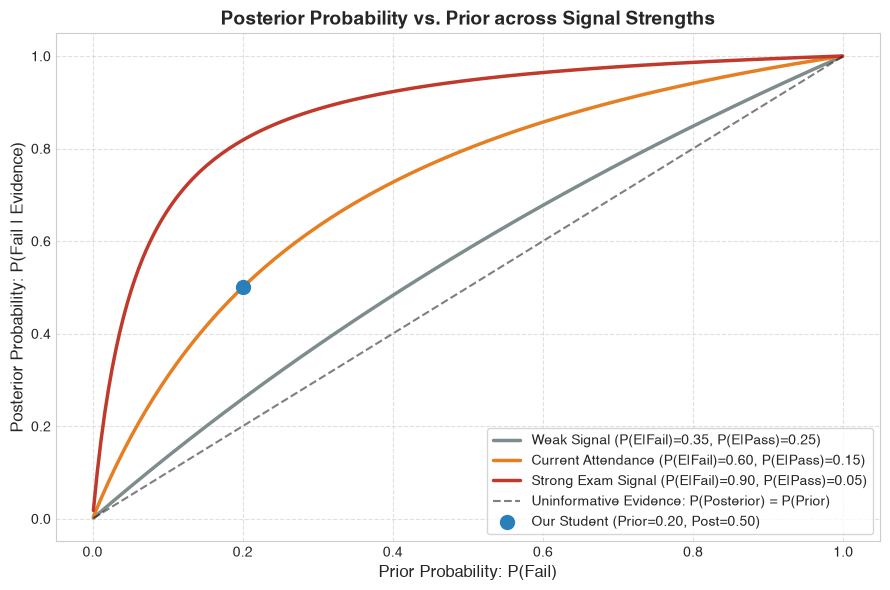

In [5]:
priors = np.linspace(0.001, 0.999, 200)

plt.figure(figsize=(9, 6))

scenarios = [
    ("Weak Signal (P(E|Fail)=0.35, P(E|Pass)=0.25)", 0.35, 0.25, "#7F8C8D"),
    ("Current Attendance (P(E|Fail)=0.60, P(E|Pass)=0.15)", 0.60, 0.15, "#E67E22"),
    ("Strong Exam Signal (P(E|Fail)=0.90, P(E|Pass)=0.05)", 0.90, 0.05, "#C0392B"),
]

for label, p_e_fail, p_e_pass, color in scenarios:
    posteriors = [bayes_posterior(pr, p_e_fail, p_e_pass)[0] for pr in priors]
    plt.plot(priors, posteriors, label=label, color=color, linewidth=2.5)

plt.plot(priors, priors, 'k--', label="Uninformative Evidence: P(Posterior) = P(Prior)", alpha=0.5)

plt.scatter([p_fail], [p_fail_given_low_att], color='#2980B9', s=100, zorder=5, label=f"Our Student (Prior={p_fail:.2f}, Post={p_fail_given_low_att:.2f})")

plt.xlabel("Prior Probability: P(Fail)", fontsize=12)
plt.ylabel("Posterior Probability: P(Fail | Evidence)", fontsize=12)
plt.title("Posterior Probability vs. Prior across Signal Strengths", fontsize=14, fontweight='bold')
plt.legend(frameon=True, facecolor='white', loc='lower right', fontsize=10)
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

## 5. Interactive Prior & Likelihood Explorer

If running in a live Jupyter environment, adjust the sliders below to explore how changes in school-wide failure rate and attendance patterns interact.
*(If rendered statically, the function displays with default parameters).*

In [6]:
def plot_interactive_bayes(prior=0.20, p_e_given_fail=0.60, p_e_given_pass=0.15):
    post, p_ev = bayes_posterior(prior, p_e_given_fail, p_e_given_pass)

    fig, ax = plt.subplots(figsize=(8, 4.5))
    bars = ax.bar(['Prior P(Fail)', 'Posterior P(Fail | Evidence)'], [prior, post], color=['#3498DB', '#E74C3C'], width=0.45)
    ax.set_ylim(0, 1.05)
    ax.set_ylabel("Probability", fontsize=12)
    ax.set_title(f"Bayesian Update\nP(Evidence) = {p_ev:.3f} | Posterior = {post:.3f} ({post*100:.1f}%)", fontsize=13, fontweight='bold')
    for b in bars:
        h = b.get_height()
        ax.text(b.get_x() + b.get_width()/2.0, h + 0.02, f"{h*100:.1f}%", ha='center', fontweight='bold', fontsize=11)
    plt.tight_layout()
    plt.show()

try:
    from ipywidgets import FloatSlider, interact
    interact(
        plot_interactive_bayes,
        prior=FloatSlider(value=0.20, min=0.01, max=0.99, step=0.01, description='Prior P(Fail):'),
        p_e_given_fail=FloatSlider(value=0.60, min=0.01, max=0.99, step=0.01, description='P(E|Fail):'),
        p_e_given_pass=FloatSlider(value=0.15, min=0.01, max=0.99, step=0.01, description='P(E|Pass):')
    )
except ImportError:
    plot_interactive_bayes(0.20, 0.60, 0.15)

interactive(children=(FloatSlider(value=0.2, description='Prior P(Fail):', max=0.99, min=0.01, step=0.01), Flo…

## 6. Beyond Single-Variable Bayes: Why We Need Bayesian Networks

So far, we worked with a single hypothesis ($Fail$) and a single piece of evidence ($LowAttendance$).

In real academic environments, a student's outcome depends on **many interdependent factors**:
- Parental education level,
- Family & school support,
- Study time,
- Past failures,
- Alcohol/social distractions,
- Prior exam scores.

If we tried to use naive single-equation Bayes with 10 variables, we would need to specify the joint distribution over all $2^{10} = 1024$ (or more) state combinations!

In **Notebook 02**, we introduce **Bayesian Networks (DAGs)** and **Conditional Independence**, which break down huge exponential joint distributions into small, tractable conditional probability tables (CPTs) via graph factorizations:

$$P(X_1, X_2, \dots, X_n) = \prod_{i=1}^n P(X_i \mid \text{Parents}(X_i))$$

---

## Recap & Key Takeaways

1. **Bayes' Rule**: Updates a prior belief $P(H)$ using the likelihood $P(E \mid H)$ and total probability of evidence $P(E)$.
2. **Base-Rate Dominance**: When the prior is rare, even tests with low false positive rates can yield modest posteriors.
3. **Student Risk Assessment**: Low attendance ($60\%$ frequency in failing students vs $15\%$ in passing students) shifted our failure probability from $20\%$ to $50\%$.
4. **Next Steps**: To model multiple interacting variables without exponential explosion, we move to **Bayesian Networks** in `02_bayesian_network.ipynb`!